# Atividade I – Bank Marketing
**Machine Learning – ESPM**

Objetivo: prever se um cliente vai aderir (`aderiu = sim`) a um depósito a prazo, comparando três classificadores
(k-NN, Naive Bayes e Regressão Logística) em dois cenários:

- **Cenário principal:** só atributos que o banco conhece *antes* de ligar.
- **Cenário completo:** todos os atributos (só para comparação).

Todas as decisões estão comentadas antes de cada bloco.

## 0. Importações e configurações

In [ ]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB, BernoulliNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
sns.set_style('whitegrid')
import os
os.makedirs('figuras', exist_ok=True)
os.makedirs('resultados', exist_ok=True)

## 1. Análise exploratória

### 1.1 Dimensões, tipos e qualidade da base

In [ ]:
df = pd.read_csv('bank_marketing_completo.csv')
print('Dimensões (linhas, colunas):', df.shape)
print()
print(df.dtypes)

Dimensões (linhas, colunas): (41188, 21)

idade                            int64
profissao                          str
estado_civil                       str
escolaridade                       str
inadimplente                       str
financiamento_imobiliario          str
emprestimo_pessoal                 str
meio_contato                       str
mes                                str
dia_semana                         str
duracao_ligacao_seg              int64
contatos_campanha_atual          int64
dias_desde_ultimo_contato        int64
contatos_anteriores              int64
resultado_campanha_anterior        str
taxa_variacao_emprego          float64
indice_precos_consumidor       float64
indice_confianca_consumidor    float64
euribor_3m                     float64
numero_empregados              float64
aderiu                             str
dtype: object


In [ ]:
print('Valores nulos no total:', df.isna().sum().sum())
print('Linhas duplicadas:', df.duplicated().sum())
print()
print(df.describe().T.round(2))

Valores nulos no total: 0
Linhas duplicadas: 12

                               count     mean     std      min      25%  \
idade                        41188.0    40.02   10.42    17.00    32.00   
duracao_ligacao_seg          41188.0   258.29  259.28     0.00   102.00   
contatos_campanha_atual      41188.0     2.57    2.77     1.00     1.00   
dias_desde_ultimo_contato    41188.0   962.48  186.91     0.00   999.00   
contatos_anteriores          41188.0     0.17    0.49     0.00     0.00   
taxa_variacao_emprego        41188.0     0.08    1.57    -3.40    -1.80   
indice_precos_consumidor     41188.0    93.58    0.58    92.20    93.08   
indice_confianca_consumidor  41188.0   -40.50    4.63   -50.80   -42.70   
euribor_3m                   41188.0     3.62    1.73     0.63     1.34   
numero_empregados            41188.0  5167.04   72.25  4963.60  5099.10   

                                 50%      75%      max  
idade                          38.00    47.00    98.00  
duracao_lig

**O que observei até aqui:**
- A base não tem valores nulos "de verdade", mas várias colunas categóricas usam a palavra `desconhecido` para dado ausente.
- Existem 12 linhas duplicadas (vou removê-las).
- `dias_desde_ultimo_contato` usa o valor 999 para "nunca foi contatado" – isso **não** é um número real de dias e atrapalharia modelos baseados em distância (k-NN).
- `duracao_ligacao_seg` só é conhecida depois que a ligação acontece (vamos tratar isso na seção 4).

In [ ]:
cat_cols_eda = df.select_dtypes(exclude='number').columns
for c in cat_cols_eda:
    print(c, '->', df[c].value_counts().to_dict())
    print()

profissao -> {'administrativo': 10422, 'operario': 9254, 'tecnico': 6743, 'servicos': 3969, 'gerencia': 2924, 'aposentado': 1720, 'empreendedor': 1456, 'autonomo': 1421, 'empregado_domestico': 1060, 'desempregado': 1014, 'estudante': 875, 'desconhecido': 330}

estado_civil -> {'casado': 24928, 'solteiro': 11568, 'divorciado': 4612, 'desconhecido': 80}

escolaridade -> {'superior': 12168, 'ensino_medio': 9515, 'fundamental_9anos': 6045, 'curso_profissionalizante': 5243, 'fundamental_4anos': 4176, 'fundamental_6anos': 2292, 'desconhecido': 1731, 'analfabeto': 18}

inadimplente -> {'nao': 32588, 'desconhecido': 8597, 'sim': 3}

financiamento_imobiliario -> {'sim': 21576, 'nao': 18622, 'desconhecido': 990}

emprestimo_pessoal -> {'nao': 33950, 'sim': 6248, 'desconhecido': 990}

meio_contato -> {'celular': 26144, 'telefone_fixo': 15044}

mes -> {'mai': 13769, 'jul': 7174, 'ago': 6178, 'jun': 5318, 'nov': 4101, 'abr': 2632, 'out': 718, 'set': 570, 'mar': 546, 'dez': 182}

dia_semana -> {'qui

In [ ]:
print('Proporção de 999 em dias_desde_ultimo_contato:', round((df['dias_desde_ultimo_contato'] == 999).mean(), 3))
print('Quantidade de "desconhecido" por coluna:')
print((df == 'desconhecido').sum()[lambda s: s > 0])

Proporção de 999 em dias_desde_ultimo_contato: 0.963
Quantidade de "desconhecido" por coluna:


profissao                     330
estado_civil                   80
escolaridade                 1731
inadimplente                 8597
financiamento_imobiliario     990
emprestimo_pessoal            990
dtype: int64


### 1.2 Distribuição da variável-alvo

aderiu
nao    36548
sim     4640
Name: count, dtype: int64
aderiu
nao    0.8873
sim    0.1127
Name: proportion, dtype: float64


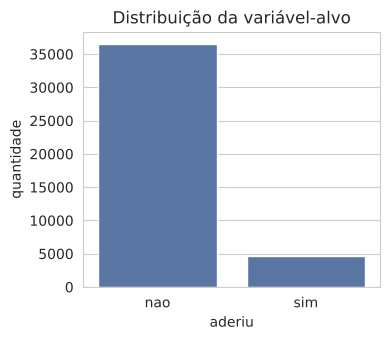

In [ ]:
contagem = df['aderiu'].value_counts()
print(contagem)
print(df['aderiu'].value_counts(normalize=True).round(4))

plt.figure(figsize=(4, 3.5))
sns.countplot(data=df, x='aderiu', order=['nao', 'sim'], color='#4C72B0')
plt.title('Distribuição da variável-alvo')
plt.xlabel('aderiu'); plt.ylabel('quantidade')
plt.tight_layout(); plt.savefig('figuras/fig1_alvo.png', dpi=150); plt.show()

**Achado importante:** a base é **desbalanceada** – só cerca de 11% dos clientes aderiram.
Um modelo que sempre responde "não" teria ~89% de acurácia e não serviria para nada. Por isso a acurácia **não** será a métrica principal.

### 1.3 Visualizações: atributos x adesão

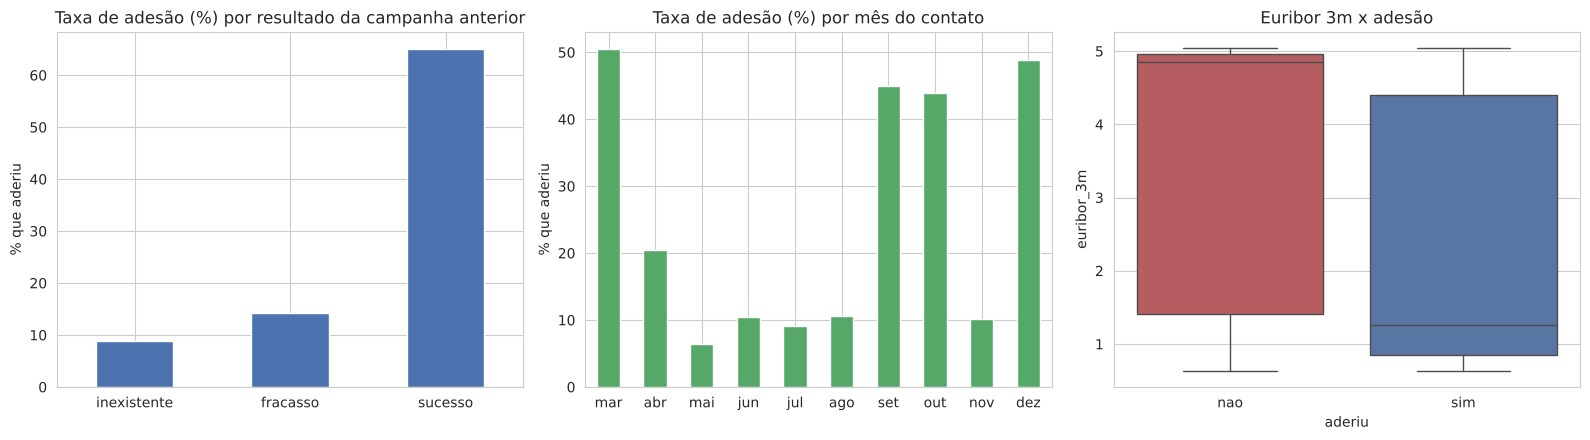

In [ ]:
df['aderiu_num'] = (df['aderiu'] == 'sim').astype(int)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

#taxa adesão p/resultado campanha ant
(df.groupby('resultado_campanha_anterior')['aderiu_num'].mean() * 100).sort_values().plot(
    kind='bar', ax=axes[0], color='#4C72B0')
axes[0].set_title('Taxa de adesão (%) por resultado da campanha anterior')
axes[0].set_xlabel(''); axes[0].set_ylabel('% que aderiu'); axes[0].tick_params(axis='x', rotation=0)

#taxa adesão p/mês
ordem_mes = ['mar', 'abr', 'mai', 'jun', 'jul', 'ago', 'set', 'out', 'nov', 'dez']
(df.groupby('mes')['aderiu_num'].mean() * 100).reindex(ordem_mes).plot(kind='bar', ax=axes[1], color='#55A868')
axes[1].set_title('Taxa de adesão (%) por mês do contato')
axes[1].set_xlabel(''); axes[1].set_ylabel('% que aderiu'); axes[1].tick_params(axis='x', rotation=0)

# eUribor
sns.boxplot(data=df, x='aderiu', y='euribor_3m', order=['nao', 'sim'], ax=axes[2], palette=['#C44E52', '#4C72B0'])
axes[2].set_title('Euribor 3m x adesão')

plt.tight_layout(); plt.savefig('figuras/fig2_atributos_x_adesao.png', dpi=150); plt.show()

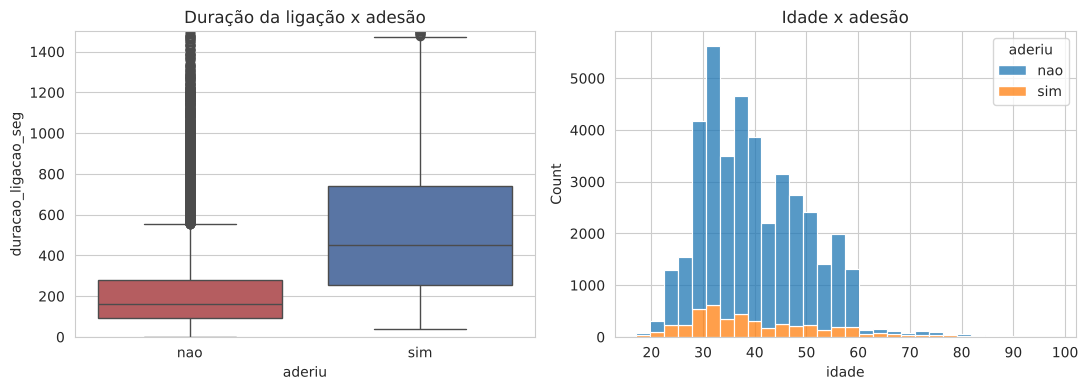

aderiu
nao    220.8
sim    553.2
Name: duracao_ligacao_seg, dtype: float64


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.boxplot(data=df, x='aderiu', y='duracao_ligacao_seg', order=['nao', 'sim'], ax=axes[0],
            palette=['#C44E52', '#4C72B0'])
axes[0].set_ylim(0, 1500)
axes[0].set_title('Duração da ligação x adesão')

sns.histplot(data=df, x='idade', hue='aderiu', bins=30, multiple='stack', ax=axes[1])
axes[1].set_title('Idade x adesão')

plt.tight_layout(); plt.savefig('figuras/fig3_duracao_idade.png', dpi=150); plt.show()

print(df.groupby('aderiu')['duracao_ligacao_seg'].mean().round(1))

**Conclusões da exploração:**
1. Clientes que já aderiram em campanha anterior (`sucesso`) têm taxa de adesão muito maior que os demais.
2. A adesão varia bastante por mês, e os meses com poucos contatos (mar, set, out, dez) têm taxas altas – o contexto do momento importa.
3. Adesões acontecem com Euribor mais baixa (cenário econômico).
4. Quem adere fica muito mais tempo no telefone, **mas essa duração só é conhecida depois da ligação** (ver seção 4).

## 2. Preparação dos dados
Alterações feitas (todas explicadas):

1. **Remover duplicatas** (12 linhas) – registros repetidos não trazem informação nova e poderiam aparecer no treino e no teste ao mesmo tempo.
2. **Tratar o 999 de `dias_desde_ultimo_contato`:** criar a coluna `nunca_contatado` (1 se era 999) e trocar o 999 por valor ausente (NaN), que será imputado pela mediana dentro do pipeline. Assim o 999 não distorce as distâncias do k-NN.
3. **Manter `desconhecido` como uma categoria** normal – o fato de o dado ser desconhecido pode ser informativo e são poucos casos.
4. **Separar treino/teste (70/30, estratificado, `random_state=42`) ANTES** de escalonar, imputar ou codificar.
5. Dentro de um `Pipeline` + `ColumnTransformer` (como nos slides): numéricas → imputação pela mediana + `StandardScaler`; categóricas → `OneHotEncoder`. Tudo é ajustado (`fit`) só no treino, evitando vazamento de dados.

In [ ]:
df = df.drop(columns=['aderiu_num'])          # coluna auxiliar dos gráficos

antes = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print('Linhas removidas:', antes - len(df), '| Linhas restantes:', len(df))

df['nunca_contatado'] = (df['dias_desde_ultimo_contato'] == 999).astype(int)
df['dias_desde_ultimo_contato'] = df['dias_desde_ultimo_contato'].replace(999, np.nan)

y = (df['aderiu'] == 'sim').astype(int)
X = df.drop(columns=['aderiu'])
print(X.shape, y.mean().round(4))

Linhas removidas: 12 | Linhas restantes: 41176
(41176, 21) 0.1127


## 3. Divisão treino/teste
30% para teste, estratificado (mantém os ~11% de "sim" nos dois conjuntos). **O teste só será usado na avaliação final.**

In [ ]:
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED)

print('Treino:', X_treino.shape, '| proporção de sim:', y_treino.mean().round(4))
print('Teste: ', X_teste.shape, '| proporção de sim:', y_teste.mean().round(4))

Treino: (28823, 21) | proporção de sim: 0.1127
Teste:  (12353, 21) | proporção de sim: 0.1127


## 4. Cenários: quais atributos o banco conhece antes de ligar?

O modelo seria usado **antes** da ligação, para decidir quem priorizar. Por isso:

- **`duracao_ligacao_seg` NÃO pode ser usada no cenário principal.** Ela só existe depois que a ligação terminou (e quem decide aderir tende a falar mais). Usar essa coluna seria "vazamento de informação": o modelo parece ótimo, mas em produção essa informação não existe no momento da decisão.
- `contatos_campanha_atual` conta também a ligação atual (inclui o último contato). Mantive no cenário principal porque, na prática, o banco sabe quantas vezes já ligou (esse valor é "ligações anteriores nesta campanha + 1"); registro isso como limitação no relatório.
- Mês, dia da semana e meio de contato são escolhas do próprio banco; os indicadores macroeconômicos já são conhecidos na data. Ficam no cenário principal.

In [ ]:
cols_num_base = ['idade', 'contatos_campanha_atual', 'dias_desde_ultimo_contato', 'contatos_anteriores',
                 'taxa_variacao_emprego', 'indice_precos_consumidor', 'indice_confianca_consumidor',
                 'euribor_3m', 'numero_empregados', 'nunca_contatado']
cols_cat = ['profissao', 'estado_civil', 'escolaridade', 'inadimplente', 'financiamento_imobiliario',
            'emprestimo_pessoal', 'meio_contato', 'mes', 'dia_semana', 'resultado_campanha_anterior']

cenarios = {
    'principal': cols_num_base,                              # sem a duração da ligação
    'completo':  cols_num_base + ['duracao_ligacao_seg'],    # com a duração (vazamento!)
}

def montar_preparacao(cols_num):
    # mesma preparação para os 3 modelos
    num = Pipeline([('imputar', SimpleImputer(strategy='median')),
                    ('escalar', StandardScaler())])
    cat = Pipeline([('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])
    return ColumnTransformer([('num', num, cols_num), ('cat', cat, cols_cat)])

for nome, cols in cenarios.items():
    print(nome, '->', len(cols) + len(cols_cat), 'atributos de entrada')

principal -> 20 atributos de entrada
completo -> 21 atributos de entrada


## 5. Escolha dos hiperparâmetros por validação cruzada
- Busca com `GridSearchCV` e `StratifiedKFold(5)`, **somente com dados de treino**.
- Para ser rápido, a busca usa uma **amostra estratificada de 10.000 linhas do treino**; depois o modelo final é treinado no treino completo.
- Métrica da busca: **F1 da classe "sim"** (justificativa na seção 6).

In [ ]:
X_amostra, _, y_amostra, _ = train_test_split(
    X_treino, y_treino, train_size=10000, stratify=y_treino, random_state=SEED)
print('Amostra para busca:', X_amostra.shape, '| proporção de sim:', y_amostra.mean().round(4))

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
melhores = {}   
tabelas_busca = {}

Amostra para busca: (10000, 21) | proporção de sim: 0.1127


### 5.1 k-NN – escolha de k

k-NN | principal: melhor k = 5 | F1 (CV) = 0.3742


k-NN | completo: melhor k = 7 | F1 (CV) = 0.4599


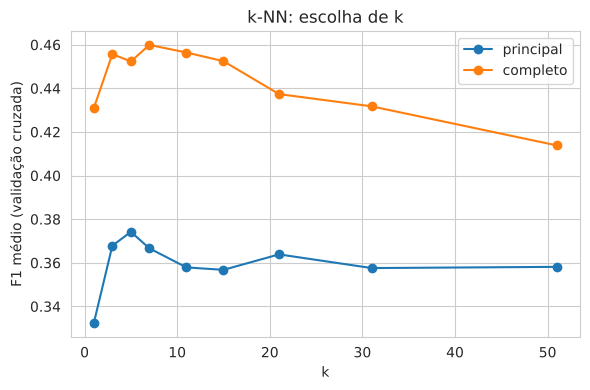

In [ ]:
grade_knn = {'modelo__n_neighbors': [1, 3, 5, 7, 11, 15, 21, 31, 51]}

for nome, cols in cenarios.items():
    pipe = Pipeline([('prep', montar_preparacao(cols)), ('modelo', KNeighborsClassifier())])
    busca = GridSearchCV(pipe, grade_knn, scoring='f1', cv=cv5, n_jobs=-1)
    busca.fit(X_amostra[cols + cols_cat], y_amostra)
    melhores[('knn', nome)] = busca.best_params_
    tabelas_busca[('knn', nome)] = busca
    print(f'k-NN | {nome}: melhor k =', busca.best_params_['modelo__n_neighbors'],
          '| F1 (CV) =', round(busca.best_score_, 4))

plt.figure(figsize=(6, 4))
for nome in cenarios:
    r = tabelas_busca[('knn', nome)].cv_results_
    plt.plot(grade_knn['modelo__n_neighbors'], r['mean_test_score'], marker='o', label=nome)
plt.xlabel('k'); plt.ylabel('F1 médio (validação cruzada)'); plt.title('k-NN: escolha de k')
plt.legend(); plt.tight_layout(); plt.savefig('figuras/fig4_knn_k.png', dpi=150); plt.show()

### 5.2 Naive Bayes – escolha da variante
Nossos atributos, depois da preparação, são: numéricas padronizadas (contínuas) e categóricas transformadas em 0/1 (one-hot).
- **GaussianNB** supõe atributos contínuos com distribuição normal. Serve para as numéricas, mas as colunas 0/1 do one-hot não são normais.
- **BernoulliNB** supõe atributos binários (0/1). Serve bem para o one-hot; as numéricas padronizadas são binarizadas no ponto 0 (acima ou abaixo da média).
- **CategoricalNB** seria a mais natural para variáveis categóricas, mas exigiria outra preparação (discretizar as numéricas e codificar categorias como números). Como a atividade pede a *mesma* preparação para os três modelos, não usei.

Comparei **GaussianNB x BernoulliNB** por validação cruzada no treino e escolhi a de maior F1.

In [ ]:
resultado_nb = {}
for nome, cols in cenarios.items():
    for variante, modelo in [('GaussianNB', GaussianNB()), ('BernoulliNB', BernoulliNB())]:
        pipe = Pipeline([('prep', montar_preparacao(cols)), ('modelo', modelo)])
        f1s = cross_val_score(pipe, X_amostra[cols + cols_cat], y_amostra, scoring='f1', cv=cv5, n_jobs=-1)
        resultado_nb[(nome, variante)] = f1s.mean()
        print(f'{nome:9s} | {variante:11s} | F1 (CV) = {f1s.mean():.4f} +/- {f1s.std():.4f}')

nb_escolhido = {}
for nome in cenarios:
    g, b = resultado_nb[(nome, 'GaussianNB')], resultado_nb[(nome, 'BernoulliNB')]
    nb_escolhido[nome] = 'GaussianNB' if g >= b else 'BernoulliNB'
print()
print('Variante escolhida:', nb_escolhido)

principal | GaussianNB  | F1 (CV) = 0.4136 +/- 0.0167


principal | BernoulliNB | F1 (CV) = 0.4046 +/- 0.0181


completo  | GaussianNB  | F1 (CV) = 0.4508 +/- 0.0181


completo  | BernoulliNB | F1 (CV) = 0.4416 +/- 0.0213

Variante escolhida: {'principal': 'GaussianNB', 'completo': 'GaussianNB'}


### 5.3 Regressão logística – escolha de C (regularização)

In [ ]:
grade_lr = {'modelo__C': [0.001, 0.01, 0.1, 1, 10, 100]}

for nome, cols in cenarios.items():
    pipe = Pipeline([('prep', montar_preparacao(cols)),
                     ('modelo', LogisticRegression(max_iter=2000, random_state=SEED))])
    busca = GridSearchCV(pipe, grade_lr, scoring='f1', cv=cv5, n_jobs=-1)
    busca.fit(X_amostra[cols + cols_cat], y_amostra)
    melhores[('lr', nome)] = busca.best_params_
    tabelas_busca[('lr', nome)] = busca
    print(f'Reg. logística | {nome}: melhor C =', busca.best_params_['modelo__C'],
          '| F1 (CV) =', round(busca.best_score_, 4))

Reg. logística | principal: melhor C = 100 | F1 (CV) = 0.3602


Reg. logística | completo: melhor C = 100 | F1 (CV) = 0.5142


## 6. Métrica principal
Só ~11% dos clientes aderem. Por isso:
- **Acurácia** engana (prever sempre "não" já dá ~89%).
- O que interessa ao banco é **encontrar os clientes que vão aderir** (recall) sem ligar para gente demais à toa (precisão).
- O **F1 da classe positiva ("sim")** equilibra precisão e recall, então é o **critério principal de comparação**.

Também olho a precisão e o recall separadamente na análise dos erros.

## 7. Treino final (treino completo) e avaliação no teste

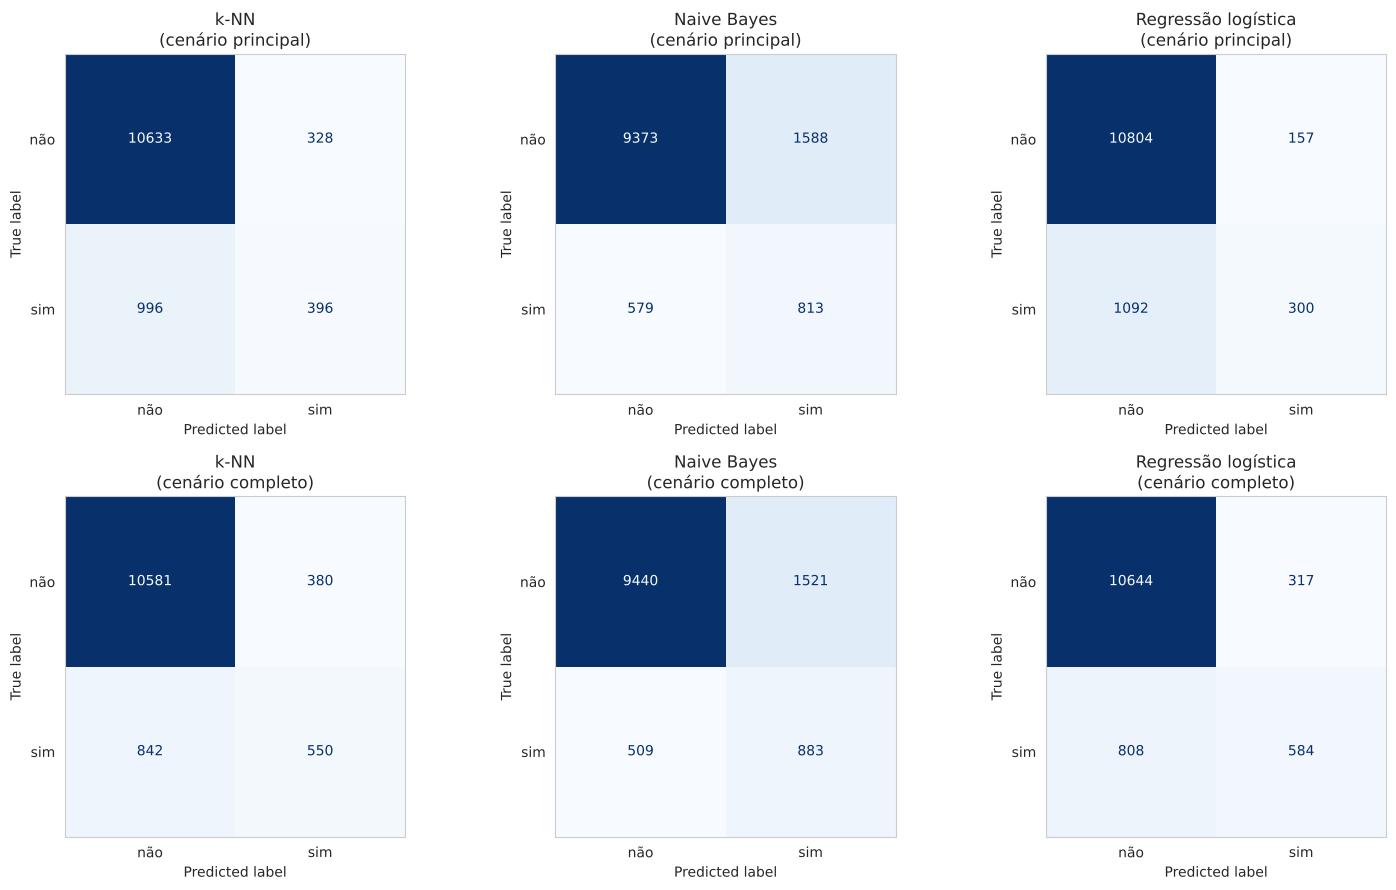

In [ ]:
def criar_modelo(tipo, cenario):
    cols = cenarios[cenario]
    if tipo == 'k-NN':
        m = KNeighborsClassifier(n_neighbors=melhores[('knn', cenario)]['modelo__n_neighbors'])
    elif tipo == 'Naive Bayes':
        m = GaussianNB() if nb_escolhido[cenario] == 'GaussianNB' else BernoulliNB()
    else:
        m = LogisticRegression(C=melhores[('lr', cenario)]['modelo__C'], max_iter=2000, random_state=SEED)
    return Pipeline([('prep', montar_preparacao(cols)), ('modelo', m)])

modelos_finais, linhas = {}, []
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for i, cenario in enumerate(cenarios):
    cols = cenarios[cenario] + cols_cat
    for j, tipo in enumerate(['k-NN', 'Naive Bayes', 'Regressão logística']):
        modelo = criar_modelo(tipo, cenario)
        modelo.fit(X_treino[cols], y_treino)
        modelos_finais[(tipo, cenario)] = modelo
        pred = modelo.predict(X_teste[cols])

        acc = accuracy_score(y_teste, pred)
        p, r, f, _ = precision_recall_fscore_support(y_teste, pred, labels=[0, 1], zero_division=0)
        linhas.append({'Cenário': cenario, 'Modelo': tipo, 'Acurácia': acc,
                       'Precisão (não)': p[0], 'Recall (não)': r[0], 'F1 (não)': f[0],
                       'Precisão (sim)': p[1], 'Recall (sim)': r[1], 'F1 (sim)': f[1]})

        cm = confusion_matrix(y_teste, pred)
        ConfusionMatrixDisplay(cm, display_labels=['não', 'sim']).plot(ax=axes[i, j], colorbar=False, cmap='Blues')
        axes[i, j].set_title(f'{tipo}\n(cenário {cenario})')
        axes[i, j].grid(False)

plt.tight_layout(); plt.savefig('figuras/fig5_matrizes_confusao.png', dpi=150); plt.show()

In [ ]:
for (tipo, cenario), modelo in modelos_finais.items():
    cols = cenarios[cenario] + cols_cat
    print('=' * 60)
    print(tipo, '| cenário', cenario)
    print(classification_report(y_teste, modelo.predict(X_teste[cols]), target_names=['não', 'sim'], digits=3))

k-NN | cenário principal


              precision    recall  f1-score   support

         não      0.914     0.970     0.941     10961
         sim      0.547     0.284     0.374      1392

    accuracy                          0.893     12353
   macro avg      0.731     0.627     0.658     12353
weighted avg      0.873     0.893     0.877     12353

Naive Bayes | cenário principal
              precision    recall  f1-score   support

         não      0.942     0.855     0.896     10961
         sim      0.339     0.584     0.429      1392

    accuracy                          0.825     12353
   macro avg      0.640     0.720     0.663     12353
weighted avg      0.874     0.825     0.844     12353

Regressão logística | cenário principal
              precision    recall  f1-score   support

         não      0.908     0.986     0.945     10961
         sim      0.656     0.216     0.324      1392

    accuracy                          0.899     12353
   macro avg      0.782     0.601     0.635     12353
we

              precision    recall  f1-score   support

         não      0.926     0.965     0.945     10961
         sim      0.591     0.395     0.474      1392

    accuracy                          0.901     12353
   macro avg      0.759     0.680     0.710     12353
weighted avg      0.889     0.901     0.892     12353

Naive Bayes | cenário completo
              precision    recall  f1-score   support

         não      0.949     0.861     0.903     10961
         sim      0.367     0.634     0.465      1392

    accuracy                          0.836     12353
   macro avg      0.658     0.748     0.684     12353
weighted avg      0.883     0.836     0.854     12353

Regressão logística | cenário completo
              precision    recall  f1-score   support

         não      0.929     0.971     0.950     10961
         sim      0.648     0.420     0.509      1392

    accuracy                          0.909     12353
   macro avg      0.789     0.695     0.730     12353
weig

## 8. Validação cruzada estratificada (5 partições) no treino – cenário principal
Média e desvio-padrão do **F1 da classe "sim"** com os hiperparâmetros já escolhidos (o teste não entra).

In [ ]:
cv_resultados = {}
cols_p = cenarios['principal'] + cols_cat
for tipo in ['k-NN', 'Naive Bayes', 'Regressão logística']:
    f1s = cross_val_score(criar_modelo(tipo, 'principal'), X_treino[cols_p], y_treino,
                          scoring='f1', cv=cv5, n_jobs=-1)
    cv_resultados[tipo] = (f1s.mean(), f1s.std())
    print(f'{tipo:20s} F1 médio = {f1s.mean():.4f} | desvio-padrão = {f1s.std():.4f}')

k-NN                 F1 médio = 0.3794 | desvio-padrão = 0.0206


Naive Bayes          F1 médio = 0.4100 | desvio-padrão = 0.0111


Regressão logística  F1 médio = 0.3450 | desvio-padrão = 0.0183


## 9. Tabela comparativa final

In [ ]:
tabela = pd.DataFrame(linhas)
tabela['F1 CV média (principal)'] = tabela.apply(
    lambda l: cv_resultados[l['Modelo']][0] if l['Cenário'] == 'principal' else np.nan, axis=1)
tabela['F1 CV desvio (principal)'] = tabela.apply(
    lambda l: cv_resultados[l['Modelo']][1] if l['Cenário'] == 'principal' else np.nan, axis=1)

hiper = []
for _, l in tabela.iterrows():
    c = l['Cenário']
    if l['Modelo'] == 'k-NN':
        hiper.append('k = ' + str(melhores[('knn', c)]['modelo__n_neighbors']))
    elif l['Modelo'] == 'Naive Bayes':
        hiper.append(nb_escolhido[c])
    else:
        hiper.append('C = ' + str(melhores[('lr', c)]['modelo__C']))
tabela['Hiperparâmetro'] = hiper

tabela = tabela.round(3)
tabela.to_csv('resultados/tabela_comparativa.csv', index=False)
tabela

,Cenário,Modelo,Acurácia,Precisão (não),Recall (não),F1 (não),Precisão (sim),Recall (sim),F1 (sim),F1 CV média (principal),F1 CV desvio (principal),Hiperparâmetro
0,principal,k-NN,0.893,0.914,0.970,0.941,0.547,0.284,0.374,0.379,0.021,k = 5
1,principal,Naive Bayes,0.825,0.942,0.855,0.896,0.339,0.584,0.429,0.410,0.011,GaussianNB
2,principal,Regressão logística,0.899,0.908,0.986,0.945,0.656,0.216,0.324,0.345,0.018,C = 100
3,completo,k-NN,0.901,0.926,0.965,0.945,0.591,0.395,0.474,NaN,NaN,k = 7
4,completo,Naive Bayes,0.836,0.949,0.861,0.903,0.367,0.634,0.465,NaN,NaN,GaussianNB
5,completo,Regressão logística,0.909,0.929,0.971,0.950,0.648,0.420,0.509,NaN,NaN,C = 100


## 10. Regressão logística: os 5 coeficientes de maior magnitude (cenário principal)
Como as numéricas foram padronizadas, os coeficientes das numéricas são comparáveis entre si. Coeficiente positivo aumenta a chance de adesão; negativo diminui. `exp(coef)` é a razão de chances.

In [ ]:
lr = modelos_finais[('Regressão logística', 'principal')]
nomes = lr.named_steps['prep'].get_feature_names_out()
coefs = pd.Series(lr.named_steps['modelo'].coef_[0], index=nomes)

top5 = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(5)
top5 = pd.DataFrame({'coeficiente': top5.round(3), 'exp(coef) = razão de chances': np.exp(top5).round(3)})
top5.to_csv('resultados/top5_coeficientes.csv')
top5

,coeficiente,exp(coef) = razão de chances
num__taxa_variacao_emprego,-2.314,0.099
cat__mes_mar,1.288,3.626
num__indice_precos_consumidor,1.120,3.064
cat__mes_jun,-0.792,0.453
cat__meio_contato_telefone_fixo,-0.686,0.503


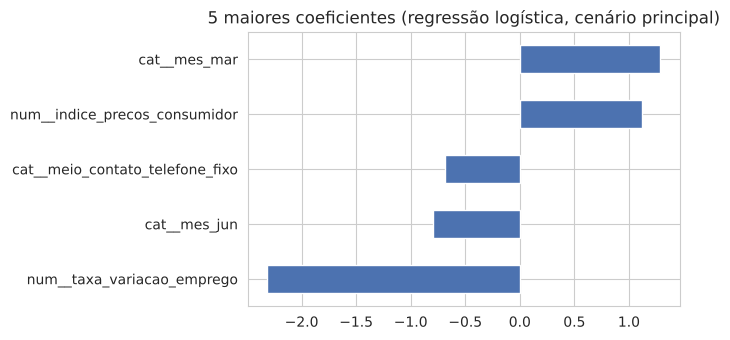

In [ ]:
plt.figure(figsize=(7, 3.5))
top5['coeficiente'].sort_values().plot(kind='barh', color='#4C72B0')
plt.title('5 maiores coeficientes (regressão logística, cenário principal)')
plt.tight_layout(); plt.savefig('figuras/fig6_coeficientes.png', dpi=150); plt.show()

## 11. Análise dos erros
- **Falso positivo (FP):** o modelo diz "vai aderir", mas o cliente não adere → o banco faz uma ligação que não rende (custo baixo: alguns minutos do operador).
- **Falso negativo (FN):** o modelo diz "não vai aderir", mas o cliente aderiria → o banco deixa de ligar e perde a venda (custo maior: perde a captação).

Em geral o FN custa mais ao banco, então o **recall da classe "sim"** merece atenção especial junto com o F1.

In [ ]:
erros = []
for (tipo, cenario), modelo in modelos_finais.items():
    cols = cenarios[cenario] + cols_cat
    tn, fp, fn, tp = confusion_matrix(y_teste, modelo.predict(X_teste[cols])).ravel()
    erros.append({'Cenário': cenario, 'Modelo': tipo, 'Verdadeiros positivos': tp, 'Falsos positivos': fp,
                  'Falsos negativos': fn, 'Verdadeiros negativos': tn})
erros = pd.DataFrame(erros)
erros.to_csv('resultados/erros.csv', index=False)
erros

,Cenário,Modelo,Verdadeiros positivos,Falsos positivos,Falsos negativos,Verdadeiros negativos
0,principal,k-NN,396,328,996,10633
1,principal,Naive Bayes,813,1588,579,9373
2,principal,Regressão logística,300,157,1092,10804
3,completo,k-NN,550,380,842,10581
4,completo,Naive Bayes,883,1521,509,9440
5,completo,Regressão logística,584,317,808,10644


## 12. Conclusões (resumo – detalhes no relatório)
- A base é desbalanceada; por isso a métrica principal foi o F1 da classe "sim".
- Ao incluir `duracao_ligacao_seg` (cenário completo), todos os modelos melhoram bastante, mas isso é **vazamento**: a duração só existe depois da ligação. Para uso real vale o **cenário principal**.
- Veja a tabela da seção 9 para escolher o melhor modelo no cenário principal.